# Testing inference: how long must the trigger be?

Retrieval is cued by only a *fragment* of the stored motif. This notebook measures the
minimal **trigger duration** `N_trigger_time` (in ms) such that showing the last
`N_trigger_time` bins of the spiking-motif (SM) window suffices for the network to re-emit
the full pattern in the evoked window. The fragment is aligned on the end of the trigger
window, where the replay starts, because the readout is only trained on complete SM
windows; the first `num_delay - N_trigger_time` bins of the trigger window prolong the
spontaneous activity. It probes the temporal completeness property of the memory
(pattern completion along time).

## Notebook summary

### Pipeline
1. Load the trained `<datetag>_vanilla.pth` (same weights as notebooks 11/13/14 - no
    retraining here).
2. Single trial with a partial trigger (`N_trigger_time = int(0.975 * num_delay)` = 39 ms) -> F1 + raster.
3. Scan `N_trigger_time = 1 .. num_delay` x `N_cv=11` seeded repetitions
    (`get_scores_fraction`) -> per-length F1 (mean, 5%-95% beta quantiles), cached as
    `<datetag>_trigger_time.npz` (+ `.lock`); plot `trigger_time_score.pdf`.
4. Theory, with no fitted parameter: first-spike theory, the ignition of the replay decided by its
    first evoked spike (`get_f1_ignition` with `N_trigger_time` bins shown, orange), and cascade
    theory, the whole replay simulated on 1000 random motifs (`get_f1_cascade`, green), overlaid on
    `trigger_time_score.pdf`.
5. Dynamics: recall of each motif against time for a few trigger durations, and open-loop
    control (`trigger_time_cascade.pdf`).

### Main outputs
- cache `../cached_data/<datetag>_trigger_time.npz` (arrays `N_trigger_times`, `scores_np`,
    `scores_motif_np`, and the `n_done` sentinel of a complete file);
- figures `trigger_time.pdf` (raster), `trigger_time_score.pdf` (F1 vs trigger length) and
    `trigger_time_cascade.pdf` (recall against time).

### Notes
- The replay is a cascade (positive feedback loop) decided by its first evoked spike. Its
    support lies in the last bins of the trigger window, so that a truncated trigger shows more of
    it than the fraction `N_trigger_time / num_delay` of the window. Until 2026-10-26 the theory
    used that fraction and required every spike evoked while the gap stayed in the window to
    fire: it underestimated the F1 score several fold. For a truncated trigger, later spikes,
    whose support is still more recent, give the motif a few more chances to ignite, so that the
    simulated cascade lies slightly above the first-spike model.


In [1]:
# Shared helpers from mnesis_boilerplate; model/algorithm from mnesis_chains.

from mnesis_boilerplate import torch, np, plt, splt, data_cache, cache_lock, figpath, RECOMPUTE, Params
from mnesis_boilerplate import printfig, get_scores, get_f1score, get_beta_errorbar, trange
from mnesis_boilerplate import get_f1_ignition, get_f1_cascade, plot_recall_time
from mnesis_chains import load
# RECOMPUTE = True

datetag = '2026-09-07'
Using device: mps


In [2]:
# Load the trained vanilla readout; the frozen pattern is the same (same seed).
opt = Params() # type: ignore
model_filename = data_cache / f"{opt.datetag}_vanilla.pth"
hd = load(opt, model_filename)
print(f"Model weights loaded from {model_filename}")

Model weights loaded from ../cached_data/2026-09-07_vanilla.pth


In [3]:
# Full production parameters (see notebook 11's Parameters table).
opt

Params(datetag='2026-09-07', N_neuron=1024, num_delay=41, N_pattern=16, N_time=1000, N_pretime=50, p_A=0.00016, p_flip=0.01, seed=2026, lif_beta=0.7, lif_threshold=0.75, learn_beta=False, learn_threshold=False, do_pinv=True, do_deconv=True, num_epochs=256, num_warmup_epochs=16, base_lr=0.04, final_lr=0.0004, delta1=0.003, delta2=1e-05, dropout=0.6, alpha_surrogate=5.0, surrogate_name='FastSigmoid', loss_name='SpikeF1scoreLoss', reset_mechanism='zero', optimizer='adadelta', verbose=False, fig_width=15.92, phi=1.61803, fig_height=9.839125356142963, N_time_show=1000, N_neuron_show=1024, i_pattern=1, N_scan=14, N_cv=11)

In [4]:
# lin (41984 -> 1024 delay-tap readout) + dropout + Leaky; eval() for deterministic probes.
hd.net.eval()

Sequential(
  (lin): Linear(in_features=41984, out_features=1024, bias=False)
  (dropout): Dropout(p=0.6, inplace=False)
  (lif): Leaky()
)

## Retrieval from a partial trigger

Single trial: `N_trigger_time = int(0.975 * num_delay)` (39 ms instead of 41): only the last
39 bins of the SM window are shown, the first 2 carry spontaneous activity. Scored on the
full evoked window against the complete target.

In [5]:
# Partial trigger: get_input_spikes shows only the last N_trigger_time bins of the SM window.

with torch.no_grad():
    target = hd.pattern_object.frozen_target # noise-free reference, scored against
    cue = hd.pattern_object(seed=hd.opt.seed) # seeded noisy realisation, provides the trigger
    N_trigger_time = int(hd.opt.num_delay*.975)
    target_full = torch.nn.functional.pad(target, (opt.N_pretime, opt.N_pretime))
    input_spikes = hd.get_input_spikes(target=cue, N_trigger_time=N_trigger_time, seed=hd.opt.seed)
    _, _, spikes = hd.forward_pass(input_spikes)
    spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    target_evoked = target[:, :, hd.opt.num_delay:]
    precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
    print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')

precision = 0.926	 recall = 0.825	 f1_score = 0.873 


### Raster of the partial-trigger trial

Legend as in notebook 11 (green `x` trigger, red `o` target, blue `+` evoked; dashed
verticals at `N_pretime` and `N_pretime + num_delay`): the green trigger only covers the
end of the trigger window, the bins before it carry spontaneous activity.

Saving as ../figures/trigger_time.pdf
Saving as ../figures/trigger_time.png
Saving as ../figures/trigger_time.svg


(torch.Size([16, 1024, 1100]), 158.0, 165.0)

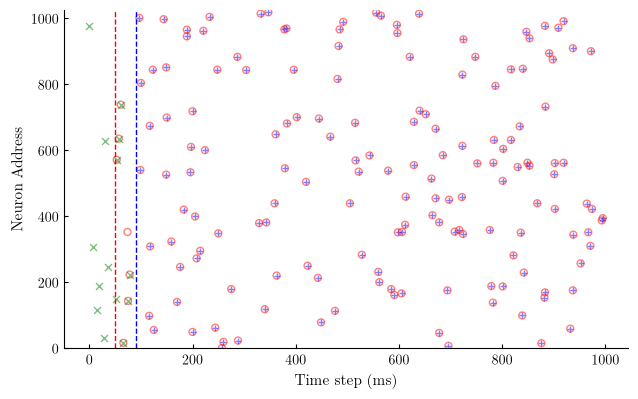

In [6]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
printfig(fig, 'trigger_time', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)
spikes.shape, spikes[opt.i_pattern, :, :].sum().item(), target[opt.i_pattern, :, :].sum().item()

## Sweep: F1 as a function of the trigger duration

`get_scores_fraction`: one forward pass per `N_trigger_time` in `1 .. num_delay`,
scoring the evoked window with `get_f1score`. The curve reveals the *critical trigger
length* at which retrieval emerges (and the floor, f1 ~ 0, for spontaneous-only cues).
Cached as `<datetag>_trigger_time.npz` under the `.lock` protocol.

In [7]:
np.arange(1, hd.opt.num_delay+1)

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41])

In [8]:
# One cue realisation per repetition (seeded nb 20-style), reduced to the last
# N_trigger_time bins of its SM window and scored against the clean frozen_target; the cache is saved after every
# trigger length with an n_done sentinel, as in notebooks 14 and 16: a partial file (an interrupted run, or one
# still being written by another process) is never mistaken for a complete one, whose unfilled rows would read F1 = 0.

def get_scores_fraction(N_cv=opt.N_cv):
    N_trigger_times = np.arange(1, hd.opt.num_delay+1)
    scores_motif_np = np.zeros((N_trigger_times.size, N_cv, hd.opt.N_pattern)) # F1 of each motif
    scores_np = np.zeros((N_trigger_times.size, N_cv))
    target_evoked = hd.pattern_object.frozen_target[:, :, hd.opt.num_delay:]
    seed = hd.opt.seed # base seed, incremented per repetition (nb 20 convention)
    for i_trigger_time in trange(N_trigger_times.size):
        N_trigger_time = N_trigger_times[i_trigger_time]
        for i_cv in range(N_cv):
            with torch.no_grad():
                target_ = hd.pattern_object(seed=seed)
                input_spikes = hd.get_input_spikes(target=target_, N_trigger_time=N_trigger_time, seed=seed)
                _, _, spikes = hd.forward_pass(input_spikes)
                spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]

                scores_np[i_trigger_time, i_cv] = get_f1score(spikes_evoked, target_evoked)
                scores_motif_np[i_trigger_time, i_cv] = get_f1score(spikes_evoked, target_evoked, dim=(1, 2)).cpu().numpy()
                seed += 1

        np.savez(npy_filename, N_trigger_times=N_trigger_times, scores_np=scores_np, scores_motif_np=scores_motif_np, n_done=i_trigger_time + 1) # incremental save

    return N_trigger_times, scores_np, scores_motif_np

# RECOMPUTE = True # overwriting the default value
npy_filename = data_cache / f"{hd.opt.datetag}_trigger_time.npz"
lock_filename = npy_filename.with_suffix('.lock')
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    data = np.load(npy_filename)
    N_trigger_times = data['N_trigger_times']
    scores_np = data['scores_np']
    if data['scores_np'].shape != (hd.opt.num_delay, opt.N_cv) or ('n_done' not in data) or (data['n_done'] != hd.opt.num_delay) or ('scores_motif_np' not in data):
        raise ValueError(f"Partial score file: {npy_filename}, re-evaluating.")
    scores_motif_np = data['scores_motif_np']
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Score weights loaded from {npy_filename}") # Add a log message
except (FileNotFoundError, ValueError):
    with cache_lock(npy_filename) as acquired:
        if acquired:
            print(f"Score file not found: {npy_filename}, evaluating the score.")
             ##################
            N_trigger_times, scores_np, scores_motif_np = get_scores_fraction()
             ##################
            np.savez(npy_filename, N_trigger_times=N_trigger_times, scores_np=scores_np, scores_motif_np=scores_motif_np, n_done=N_trigger_times.size)
        else:
            print(f"Score file is locked: {lock_filename}, passing.")

Score weights loaded from ../cached_data/2026-09-07_trigger_time.npz


## Expected F1 from theory

The ignition model of notebook 14 (`get_f1_ignition`) applies to a trigger reduced to the last
$L$ bins of its window. With the minimum-norm (pseudo-inverse) readout, a spike of a motif is
supported, with equal weights, by the $K$ spikes of that motif in the $D$ bins before it, and is
emitted if at least $\lceil \vartheta K \rceil$ of them are present, $\vartheta$ being the firing
threshold; a spike of the spontaneous activity that fills the first $D - L$ bins falls on a
near-zero weight. The replay is a cascade, a positive feedback loop: each emitted spike joins the support of the
next ones. Once the first evoked spike of a motif is emitted, the following ones find more and more
of their support, and the replay ignites as a whole and sustains itself; if it fails, their support
keeps shrinking and the replay dies out (see the dynamics below). The ignition probability $R$ is
thus that of the first evoked spike. A motif fires $\mu = p_A N$ spikes per bin, so this spike
comes $j$ bins after the trigger with probability $P(j) = e^{-\mu j}(1 - e^{-\mu})$, and its $K$
supporting spikes, in the last $D - j$ bins of the trigger window, follow a Poisson law of mean
$\lambda_j = \mu (D - j)$. A supporting spike is present if it lies in the $L$ bins
shown and survives the flips of the cue (bit-flip probability $p_\mathrm{flip}$, firing probability
$p_A$), with probability

$$q_j = \frac{\min(L, D - j)}{D - j}\,\big(1 - p_\mathrm{flip}\,(1 - p_A)\big),$$

larger than the fraction $L / D$ of the window: the support of the first evoked spike is more
recent than a whole window, and so better shown. The ignition probability is

$$R = \frac{1}{R_0} \sum_{j=0}^{D-1} P(j) \sum_{K \geq 1} \frac{e^{-\lambda_j} \lambda_j^K}{K!} \sum_{k = \lceil \vartheta K \rceil}^{K} \binom{K}{k}\, q_j^k (1 - q_j)^{K - k},$$

normalised by its value $R_0 \approx 0.991$ for the intact trigger ($q_j = 1$: the first evoked
spike fires if it has at least one supporting spike), whose rare failures are already counted in
the measured recall.

As in notebook 14, $F_1 = 2\, R\, r_0 / (1 + R\, r_0 / \pi_0)$, with $\pi_0$ and $r_0$ the precision
and recall with the full trigger ($L = D$).

**Two theories.** The formula above is the *first-spike theory* (orange line): it computes, in
closed form, only the first step of the cascade, averaged over the Poisson statistics of the
support. The *cascade theory* (green line, `get_f1_cascade`) simulates the whole replay instead:
1000 random motifs with the same statistics and the whole duration $T$, bin after bin, the emitted
spikes joining the support of the next ones, with the identity of the neurons kept in the trigger
window. The two theories agree when the first evoked spike decides the replay. Neither has a
fitted parameter: the threshold is the LIF threshold of the network, and only $\pi_0$ and $r_0$
are measured. For a truncated trigger, later evoked spikes, whose support is still
more recent, give a motif a few more chances to ignite when the first one fails, so that the green
line lies slightly above the orange one.

| symbol | name in the code | default value | role |
|---|---|---|---|
| $L$ | `N_trigger_time` | swept from 1 to 41 bins (1 to 41 ms) | trigger duration, shown at the end of the window |
| $D$ | `num_delay` | 41 bins (41 ms) | width of the spiking-motif window |
| $N$ | `N_neuron` | 1024 | number of neurons |
| $p_\mathrm{flip}$ | `p_flip` | 0.01 | bit-flip probability of the cue |
| $p_A$ | `p_A` | $1.6 \times 10^{-4}$ per 1 ms bin (0.16 Hz) | firing probability of the motif |
| $\vartheta$ | `lif_threshold` | 0.75 | firing threshold, relative to the membrane potential reached on the motif |
| $\mu$ | `p_A * N_neuron` | 0.164 spike per bin | mean number of spikes of a motif per bin |
| $j$ | - | 0 to $D - 1$ bins (mean 5.6 ms) | delay of the first evoked spike after the trigger |
| $\lambda_j$ | `mu * (num_delay - j)` | 6.72 for $j = 0$ | mean number of spikes supporting the first evoked spike |
| $q_j$ | `get_trigger_presence` | - | probability that a spike supporting the first evoked spike is present in the trigger |
| $R$, $R_0$ | - | $R_0 \approx 0.991$ | ignition probability of a motif, and its value with an intact trigger |
| $\pi_0$, $r_0$ | `precision_0`, `recall_0` | measured with $L = D$ | precision and recall with the full trigger |

The cell below measures $\pi_0$ and $r_0$ with the first repetition of the sweep protocol (same
seed, full trigger), evaluates both theories, and reports their RMS error on the sweep. In the score
figure, the orange line is the first-spike theory, the green line the cascade theory, and the grey
dashed lines mark $F_1 = 0$ and $F_1 = 1$.

In [9]:
# Precision and recall of the replay with the full trigger (first repetition of the sweep
# protocol, same seed): the only measured inputs of the ignition model.

with torch.no_grad():
    target_ = hd.pattern_object(seed=opt.seed)
    _, _, spikes = hd.forward_pass(hd.get_input_spikes(target=target_, N_trigger_time=opt.num_delay, seed=opt.seed))
    spikes_evoked = spikes[:, :, (opt.N_pretime+opt.num_delay):(opt.N_time+opt.N_pretime)]
    target_evoked = hd.pattern_object.frozen_target[:, :, opt.num_delay:]
    precision_0, recall_0, f1_score_0 = [score.item() for score in get_scores(spikes_evoked, target_evoked)]
print(f'full trigger: precision = {precision_0:.3f}\t recall = {recall_0:.3f}\t f1_score = {f1_score_0:.3f}')

theory_dict = dict(p_flip=opt.p_flip, p_A=opt.p_A, N_neuron=opt.N_neuron, num_delay=opt.num_delay,
                   lif_threshold=opt.lif_threshold, precision_0=precision_0, recall_0=recall_0)
# partial trigger: the last L bins of the window are shown
N_trigger_times_theory = np.arange(1, opt.num_delay+1) # the model is defined on whole bins
f1_ignition_theory = get_f1_ignition(N_trigger_time=N_trigger_times_theory, **theory_dict)
f1_cascade_theory = get_f1_cascade(N_trigger_time=N_trigger_times_theory, N_time=opt.N_time, **theory_dict) # whole replay, simulated
if not lock_filename.exists():
    for name, f1_scan in [('first-spike', get_f1_ignition(N_trigger_time=N_trigger_times, **theory_dict)),
                          ('cascade', get_f1_cascade(N_trigger_time=N_trigger_times, N_time=opt.N_time, **theory_dict))]:
        print(f'RMS error of the {name} theory on the sweep = {np.sqrt(np.mean((f1_scan - scores_np.mean(axis=1))**2)):.3f}')

full trigger: precision = 0.835	 recall = 0.825	 f1_score = 0.830


RMS error of the first-spike theory on the sweep = 0.055
RMS error of the cascade theory on the sweep = 0.052


Saving as ../figures/trigger_time_score.pdf
Saving as ../figures/trigger_time_score.png
Saving as ../figures/trigger_time_score.svg


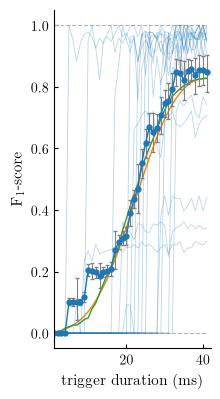

In [10]:
# $F_1$ vs trigger duration (ms), mean and 5%-95% quantiles of a beta fit over N_cv realisations; thin lines for each motif; grey guides at 0 and 1;
# orange: first-spike theory; green: cascade theory.

if not lock_filename.exists():
    fig, ax = plt.subplots()
    ax.hlines([0, 1], N_trigger_times[0], N_trigger_times[-1], '0.7', ls='--', lw=0.8)
    ax.plot(N_trigger_times_theory, f1_ignition_theory, color='tab:orange')
    ax.plot(N_trigger_times_theory, f1_cascade_theory, color='tab:green')
    # one thin line per motif (F1 of the motif, mean over the N_cv realisations), overlaid on the
    # mean: each motif switches from 0 to its intact value at its own threshold (all-or-nothing ignition)
    ax.plot(N_trigger_times, scores_motif_np.mean(axis=1), color='tab:blue', alpha=.3, lw=.6)
    mean, yerr = get_beta_errorbar(scores_np)
    ax.errorbar(N_trigger_times, mean, yerr=yerr, fmt='o',
                color='tab:blue', ecolor='0.5', elinewidth=0.8, capsize=1.5,
                markersize=3.5, linestyle='solid', linewidth=1.0)
    ax.set_xlabel(r"trigger duration (ms)")
    ax.set_ylabel(r"$F_1$-score")
    ax.set_xlim(N_trigger_times[0], N_trigger_times[-1]+1)
    ax.set_ylim(-0.05, 1.05)

    printfig(fig, 'trigger_time_score', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)


## Dynamics of the replay: a cascade

The ignition model assumes that the replay of each motif either ignites as a whole and sustains
itself, or dies out. The recall of each motif in successive windows of $D = 41$ ms of the evoked
window (`HD_SNN.get_recall_time`) shows it directly, for a few trigger durations (thin lines: single
motifs; thick lines: mean over the $M = 16$ motifs): each motif settles on the recall of the
intact trigger or on zero, a bistable dynamics, and the truncation only changes the number of
motifs that ignite. In the open-loop control (dashed black, `forward_pass(..., feedback=False)`,
with the intact trigger), the output spikes are not fed back: each neuron only sees the trigger,
which drives the first $D$ ms of the evoked window, after which the activity vanishes. The replay
is thus sustained by the recurrent positive feedback, not by the trigger. A few motifs stop late
in the evoked window even with the intact trigger: these failures do not depend on the trigger and
are part of the measured recall $r_0$.

Saving as ../figures/trigger_time_cascade.pdf
Saving as ../figures/trigger_time_cascade.png
Saving as ../figures/trigger_time_cascade.svg


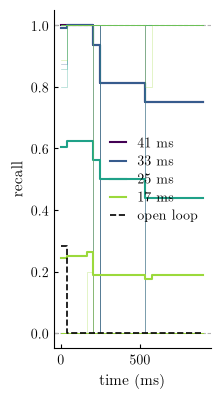

In [11]:
# Recall of each motif per window of num_delay bins for a few trigger durations (closed loop),
# and for the open-loop control (output spikes not fed back) with the full trigger.

N_trigger_time_levels = [opt.num_delay, 33, 25, 17]
cue = hd.pattern_object(seed=opt.seed)
recall_time = [hd.get_recall_time(hd.get_input_spikes(target=cue, N_trigger_time=N_trigger_time, seed=opt.seed))
               for N_trigger_time in N_trigger_time_levels]
recall_open = hd.get_recall_time(hd.get_input_spikes(target=cue, seed=opt.seed), feedback=False)
labels = [f'{N_trigger_time} ms' for N_trigger_time in N_trigger_time_levels]

fig, ax = plt.subplots()
plot_recall_time(ax, recall_time, labels, recall_open=recall_open, bin_width=opt.num_delay)
ax.legend(loc='center right', handlelength=1.2, labelspacing=0.3)
printfig(fig, 'trigger_time_cascade', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)